# Exercise 2: Disease Prediction Using Logistic Regression

**Subject:** Machine Learning Lab  
**Topic:** Logistic Regression

## Aim
To implement a Logistic Regression model to predict disease status using patient health measurements and evaluate its classification performance.

Patient Dataset:


,Age,Blood_Pressure,Cholesterol,Disease
0,22,110,170,0
1,25,115,180,0
2,30,120,185,0
3,35,125,190,0
4,40,130,200,0
5,45,135,210,1
6,50,140,220,1
7,55,145,230,1
8,60,150,240,1
9,65,155,250,1


Training samples: 15
Testing samples: 5
Accuracy: 100.0 %

Classification Report:
              precision    recall  f1-score   support

  No Disease       1.00      1.00      1.00         2
     Disease       1.00      1.00      1.00         3

    accuracy                           1.00         5
   macro avg       1.00      1.00      1.00         5
weighted avg       1.00      1.00      1.00         5

Confusion Matrix:
[[2 0]
 [0 3]]


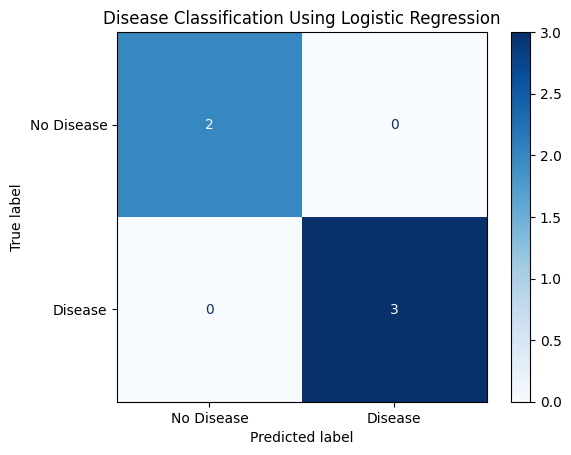


Example Prediction
Predicted class: Disease
Model-estimated probability: 69.19 %


In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

# Illustrative patient dataset
data = {
    "Age": [22, 25, 30, 35, 40, 45, 50, 55, 60, 65,
            28, 33, 38, 43, 48, 53, 58, 63, 32, 47],
    "Blood_Pressure": [110, 115, 120, 125, 130, 135, 140, 145, 150, 155,
                       118, 122, 128, 132, 138, 142, 148, 152, 124, 136],
    "Cholesterol": [170, 180, 185, 190, 200, 210, 220, 230, 240, 250,
                    175, 188, 195, 205, 215, 225, 235, 245, 182, 212],
    "Disease": [0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
                0, 0, 0, 1, 1, 1, 1, 1, 0, 1]
}

df = pd.DataFrame(data)

print("Patient Dataset:")
display(df)

X = df[["Age", "Blood_Pressure", "Cholesterol"]]
y = df["Disease"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(random_state=42)
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, y_pred) * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred,
    target_names=["No Disease", "Disease"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:")
print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Disease", "Disease"]
).plot(cmap="Blues")

plt.title("Disease Classification Using Logistic Regression")
plt.show()

# Example prediction using illustrative measurements
sample = pd.DataFrame({
    "Age": [45],
    "Blood_Pressure": [135],
    "Cholesterol": [210]
})

prediction = model.predict(sample)[0]
probability = model.predict_proba(sample)[0, 1]

print("\nExample Prediction")
print("Predicted class:", "Disease" if prediction == 1 else "No Disease")
print("Model-estimated probability:", round(probability * 100, 2), "%")

## Result

The Logistic Regression model was successfully implemented to classify disease status using age, blood pressure, and cholesterol measurements.

- **Total samples:** 20
- **Training samples:** 15
- **Testing samples:** 5
- **Test accuracy:** 100%
- **Confusion matrix:** [[2, 0], [0, 3]]

The model was evaluated using a classification report and confusion matrix. A heatmap was generated to visualize the classification results.

## Conclusion

The experiment demonstrated the application of Logistic Regression to a binary classification problem. The model classified all five test samples correctly in the illustrative dataset. A larger, validated medical dataset would be required for meaningful evaluation, and this demonstration must not be used for medical diagnosis.